In [11]:
%matplotlib widget
import os
import numpy as np
import pandas as pd
import glob2 as gb
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch
import time


mpl.rcParams['keymap.pan'] = ['d']
mpl.rcParams['keymap.zoom'] = ['z']
# mpl.rcParams['font.size'] = 14

# plt.figure(figsize=(12,4))

In [12]:
top20 = ['0441', '0013', '0089', '0152', '0021', '0061', '0340', '0418', '0170', '0080', '0435', '0224', '0379', '0351', '0147', '0439', '0338', '0336', '0208', '0516']

phase_name = 'alpha'
refinement_type = 'single' # 'single' or 'vc'
parent_path = f'./TOPAS/{phase_name}/full_sg_tree_constrained'
expt_path =  f'./TOPAS/alpha/experimental_refinement/P1_{refinement_type}_refinement'
bin_edges_file = f'TOPAS/alpha/bin_edges_C0p0008.txt'
perturb_path = f'TOPAS/alpha/ML_data_generation'

def get_xy_perturb(perturb_path, cifnumber, statenumber):
    xy_path = f'{perturb_path}/cif{cifnumber}/random_state_{statenumber}_simulated_xy.xy'
    xy = pd.read_csv(xy_path, sep='\s+', header = None, names = ['x','y'])
    return xy

def get_hkl_perturb(perturb_path, cifnumber, statenumber):
    hkl_path = f'{perturb_path}/cif{cifnumber}/random_state_{statenumber}_hkl.dat'
    hkl = pd.read_csv(hkl_path, sep='\s+', header = None, names = ['h','k', 'l', 'm', 'd', 'tof', 'i'], usecols=['d','i'])
    hkl_tensor = torch.tensor(hkl.values)
    return hkl_tensor


def get_xy_data(parent_path, cifnumber):
    xy_path = f'{parent_path}/{cifnumber}/02_pawley_refinement/simulated_xy_cif{cifnumber}.xy'
    xy = pd.read_csv(xy_path, sep='\s+', header = None, names = ['x','y'])
    return xy

def get_hkl_data(parent_path, cifnumber):
    hkl_path = f'{parent_path}/{cifnumber}/02_pawley_refinement/hkl_cif{cifnumber}.dat'
    hkl = pd.read_csv(hkl_path, sep='\s+', header = None, names = ['h','k', 'l', 'm', 'd', 'tof', 'i'], usecols=['d','i'])
    hkl_tensor = torch.tensor(hkl.values)
    return hkl_tensor

def get_expt_xy(expt_path, refinement_type):
    expt_file = f'{expt_path}/simulated_xy_expt_{refinement_type}_P1_latparams.xy'
    expt_xy = pd.read_csv(expt_file, sep='\s+', header = None, names = ['x','y'])
    return expt_xy

def get_expt_hkl(expt_path, refinement_type):
    expt_file = f'{expt_path}/hkl_expt_{refinement_type}_P1_latparams.dat'
    expt_hkl = pd.read_csv(expt_file, sep='\s+', header = None, names = ['h','k', 'l', 'm', 'd', 'tof', 'i'], usecols=['d','i'])
    hkl_tensor = torch.tensor(expt_hkl.values)
    return hkl_tensor

def get_custom_data(full_path):
    xy = pd.read_csv(full_path, sep='\s+', header = None, names = ['x','y'])
    return xy

def bin_tensor(tensor_to_bin, bin_edges):
    binned_tensor = torch.zeros_like(bin_edges)
    bucket_tensor = torch.bucketize(tensor_to_bin[:,0], bin_edges, right=False)
    for index,value in zip(bucket_tensor, tensor_to_bin[:,1]):
        binned_tensor[index] += value
    return binned_tensor

In [13]:
statenumber = '0008'
perturbcif = '0001'
# get unperturbed data
xy_expt = get_expt_xy(expt_path, refinement_type)
xy_0548 = get_xy_data(parent_path, '0548')
xy_0088 = get_xy_data(parent_path, '0088')
xy_0547 = get_xy_data(parent_path, '0547')

hkl_expt = get_expt_hkl(expt_path, refinement_type)
hkl_0548 = get_hkl_data(parent_path, '0548')
hkl_0088 = get_hkl_data(parent_path, '0088')
hkl_0547 = get_hkl_data(parent_path, '0547')

# get perturbed data
pxy_0548 = get_xy_perturb(perturb_path, '0548', '0001')
phkl_0548 = get_hkl_perturb(perturb_path, '0548', '0001')
pxy_0088 = get_xy_perturb(perturb_path, '0088', '0001')
phkl_0088 = get_hkl_perturb(perturb_path, '0088', '0001')
pxy_0547 = get_xy_perturb(perturb_path, '0547', '0001')
phkl_0547 = get_hkl_perturb(perturb_path, '0547', '0001')

# load bin edges
bin_edges = torch.tensor(np.loadtxt(bin_edges_file))



In [14]:
yp_path = f'./TOPAS/alpha/testing_yp_jan25/random_state_0008_simulated_xy.xy'
xy_yp_0mode = get_custom_data(yp_path)

nothing_path = f'./TOPAS/alpha/testing_yp_jan25/random_state_0008_simulated_xy.xy'
xy_yp_perturb = get_xy_perturb(perturb_path, '0001', '0001')

In [23]:
# bin hkls
hkl_expt_binned = bin_tensor(hkl_expt, bin_edges)
hkl_0548_binned = bin_tensor(hkl_0548, bin_edges)
hkl_0088_binned = bin_tensor(hkl_0088, bin_edges)
hkl_0547_binned = bin_tensor(hkl_0547, bin_edges)

phkl_0548_binned = bin_tensor(phkl_0548, bin_edges)
phkl_0088_binned = bin_tensor(phkl_0088, bin_edges)
phkl_0547_binned = bin_tensor(phkl_0547, bin_edges)

# phkl_0547_binned = bin_tensor(phkl_0547, bin_edges)

scale_xy = 1
scale_hkl = .1
# for i in range(len(phkl_0547_binned)):
#     phkl_0547_binned[i] = scale*phkl_0547_binned[i]

# for i in range(len(pxy_0547['y'])):
#     pxy_0547['y'][i] = scale*pxy_0547['y'][i]

# for i in range(len(xy_yp_0mode['y'])):
#     xy_yp_0mode['y'][i] = scale*xy_yp_0mode['y'][i]
#     xy_yp_perturb['y'][i] = scale*xy_yp_perturb['y'][i]


for i in range(len(pxy_0547['y'])):
    pxy_0547['y'][i] = scale_xy*pxy_0547['y'][i]

for i in range(len(phkl_0547_binned)):
    phkl_0547_binned[i] = phkl_0547_binned[i]*scale_hkl

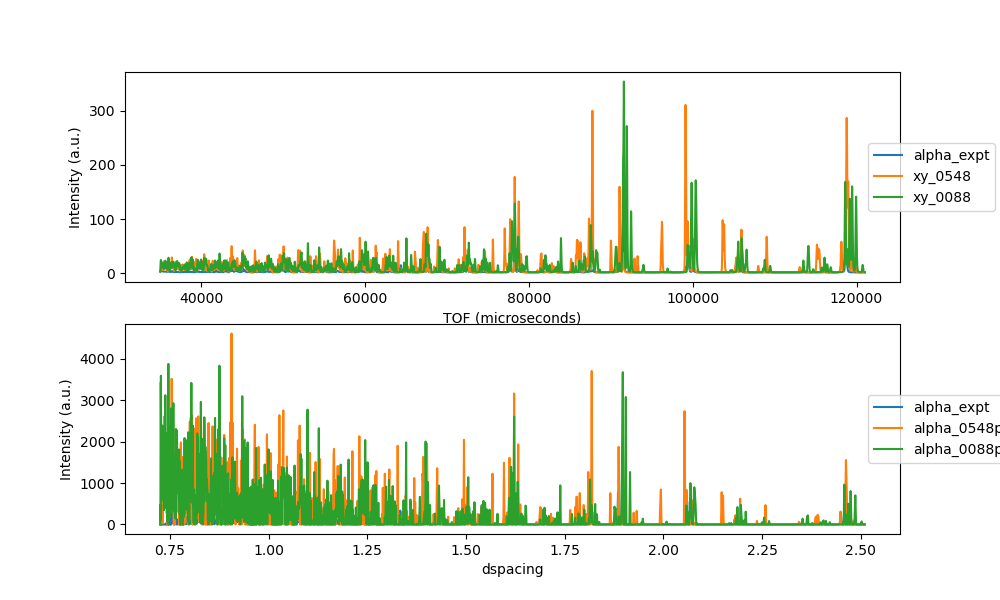

In [25]:
fig, (ax_pxy, ax_phkl) = plt.subplots(2, figsize=(10,6))
#ax_xy, ax_hkl, ax_xy_yp, 
# ax_xy.plot(xy_expt['x'], xy_expt['y'], label= f'{phase_name}_expt')
# ax_xy.plot(xy_0548['x'], xy_0548['y'], label=f'{phase_name}_0548')
# ax_xy.plot(xy_0088['x'], xy_0088['y'], label=f'{phase_name}_0088')
# ax_xy.plot(xy_0547['x'], xy_0547['y'], label=f'{phase_name}_0547')
# # ax_xy.plot(pxy_0547['x'], pxy_0547['y'], label=f'{phase_name}_p{perturbcif}')

# # for i in predictions_to_plot:
# #     ax_xy.plot(xy_of_interest[i]['x'], xy_of_interest[i]['y'], label=f'{phase_label}{model_label}_xy_{subgroups_of_interest[i]}')
# ax_xy.set_xlabel('TOF (microseconds)')
# ax_xy.set_ylabel('Intensity (a.u.)')
# ax_xy.legend(loc='center left', bbox_to_anchor=(.95, 0.5))


# #---------------------------------------------------------
# # PLOT BINNED HKLS
# #---------------------------------------------------------

# ax_hkl.plot(bin_edges, hkl_expt_binned, label = f'{phase_name}_expt')
# ax_hkl.plot(bin_edges, hkl_0548_binned, label=f'{phase_name}_0548')
# ax_hkl.plot(bin_edges, hkl_0088_binned, label=f'{phase_name}_0088')
# ax_hkl.plot(bin_edges, hkl_0547_binned, label = f'{phase_name}_0547')
# # ax_hkl.plot(bin_edges, phkl_0547_binned, label = f'{phase_name}_p{perturbcif}')
# ax_hkl.set_xlabel('dspacing')
# ax_hkl.set_ylabel('Intensity (a.u.)')
# ax_hkl.legend(loc='center left', bbox_to_anchor=(.95, 0.5))



# ax_xy_yp.plot(xy_expt['x'], xy_expt['y'], label= f'{phase_name}_expt')
# ax_xy_yp.plot(xy_0547['x'], xy_0547['y'], label=f'{phase_name}_0547')
# ax_xy_yp.plot(xy_yp_0mode['x'], xy_yp_0mode['y'], label='0001 0mode perf')
# # ax_xy_yp.plot(xy_yp_perturb['x'], xy_yp_perturb['y'], label='0001 perturb')

# ax_xy_yp.set_xlabel('TOF (microseconds)')
# ax_xy_yp.set_ylabel('Intensity (a.u.)')
# ax_xy_yp.legend(loc='center left', bbox_to_anchor=(.95, 0.5))

ax_pxy.plot(xy_expt['x'], xy_expt['y'], label= f'{phase_name}_expt')
ax_pxy.plot(pxy_0548['x'], pxy_0548['y'], label = 'xy_0548')
ax_pxy.plot(pxy_0088['x'], pxy_0088['y'], label = 'xy_0088')
# ax_pxy.plot(pxy_0547['x'], pxy_0547['y'], label = 'xy_0547')
ax_pxy.set_xlabel('TOF (microseconds)')
ax_pxy.set_ylabel('Intensity (a.u.)')
ax_pxy.legend(loc='center left', bbox_to_anchor=(.95, 0.5))

ax_phkl.plot(bin_edges, hkl_expt_binned, label = f'{phase_name}_expt')
ax_phkl.plot(bin_edges, phkl_0548_binned, label=f'{phase_name}_0548p')
ax_phkl.plot(bin_edges, phkl_0088_binned, label=f'{phase_name}_0088p')
# ax_phkl.plot(bin_edges, phkl_0547_binned, label = f'{phase_name}_0547p')
ax_phkl.set_xlabel('dspacing')
ax_phkl.set_ylabel('Intensity (a.u.)')
ax_phkl.legend(loc='center left', bbox_to_anchor=(.95, 0.5))

In [17]:


# for i in predictions_to_plot:
#     ax_hkl.plot(bin_edges_tensor, hkl_tensor_list[i], label=f'{phase_label}{model_label}_hkl_{subgroups_of_interest[i]}')
ax_hkl.set_xlabel('d-space (Angstroms)')
ax_hkl.set_ylabel('Intensity (a.u.)')
ax_hkl.legend(loc='center left', bbox_to_anchor=(.95, 0.5))
# plt.savefig('./alpha_branch_xy_compare.png', dpi=300, bbox_inches='tight')
fig.show

<bound method Figure.show of <Figure size 1500x1500 with 5 Axes>>